# Visualisations of the Tracked _Real_ Events (OSTIA Observations) using `plotX`

To make the same figures for the basic tracking, open `events_basic.zarr` in place of `events_merged.zarr` below.

In [1]:
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import dask
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import Video

import marEx
import marEx.helper as hpc

2026-10-11 22:09:27 - marEx - INFO - [PID:2052064] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
out_dir = scratch_dir / "marEx" / "examples" / "gridded"  # where notebooks 01 and 02 wrote their output
plot_dir = out_dir / "plots"

movie_period = slice("2020-01-01", "2022-05-31")
example_days = slice("2021-01-01", "2021-01-06")
example_year = slice("2021-01-01", "2021-12-31")

# Movie frames render one per task without threads: 16 single-threaded workers x 7 GB
n_workers, threads_per_worker, memory_limit = 16, 1, "7GB"

In [3]:
plot_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is passed explicitly because on an HPC node Dask sizes workers from the whole node's memory,
# not from the job's allocation, and without it the workers can claim more than the job was granted.
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-11 22:09:32 - marEx.helper.cluster - INFO - [PID:2052064] - Starting local Dask cluster with 16 workers, 1 threads each


2026-10-11 22:09:32 - marEx.helper.dask_config - INFO - [PID:2052064] - Configuring Dask for HPC environment


2026-10-11 22:09:32 - marEx.helper.dask_config - INFO - [PID:2052064] - Dask temporary directory: /scratch/b/b382615/marEx/dask/tmpwfieavka


2026-10-11 22:09:32 - marEx.helper.dask_config - INFO - [PID:2052064] - Dask configuration completed


2026-10-11 22:09:32 - marEx.helper.cluster - INFO - [PID:2052064] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


...

2026-10-11 22:09:32 - marEx.helper.cluster - INFO - [PID:2052064] - Starting Local cluster startup


2026-10-11 22:09:34 - marEx.helper.cluster - INFO - [PID:2052064] - Completed Local cluster startup in 1.84s


Hostname: l40008
Forward Port: l40008:8787
Dashboard Link: localhost:8787/status
2026-10-11 22:09:34 - marEx.helper.cluster - INFO - [PID:2052064] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-10-11 22:09:34 - marEx.helper.cluster - INFO - [PID:2052064] - After cluster startup - Memory Usage - RSS: 575.5MB, Virtual: 27291.3MB, Percent: 0.2%, Available: 236214.5MB


2026-10-11 22:09:34 - marEx.helper.resources - INFO - [PID:2052064] - Cluster: 16 workers, 16 threads, memory_limit per worker [7.0] GB (112 GB total)


In [4]:
extremes_ds = xr.open_zarr(out_dir / "extremes_shifting_hobday.zarr", chunks={})
extremes_ds

<xarray.Dataset> Size: 50GB
Dimensions:         (time: 9282, lat: 720, lon: 1440, dayofyear: 366)
Coordinates:
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
  * lat             (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon             (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time            (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-0...
Data variables:
    dat_anomaly     (time, lat, lon) float32 38GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 10GB dask.array<chunksize=(25, 720, 1440), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(720, 1440), meta=np.ndarray>
    thresholds      (lat, lon, dayofyear) float32 2GB dask.array<chunksize=(720, 1440, 25), meta=np.ndarray>
Attributes:
    max_anomaly:           21.038787841796875
    method_anomaly:        shifting_baseline
    method_extreme:        seasonal_percentile
    method_percentile:     approximate
    precision:             0.014025858561197917
    preprocessing_steps:   ['Rolling climatology using 15 years', 'Smoothed w...
    smooth_days:           21
    tail:                  upper
    threshold_percentile:  95
    window_days:           11
    window_spatial:        5
    window_years:          15

In [5]:
extreme_events_ds = xr.open_zarr(out_dir / "events_merged.zarr", chunks={})
extreme_events_ds

<xarray.Dataset> Size: 45GB
Dimensions:       (ID: 9295, time: 9282, lat: 720, lon: 1440, component: 2,
                   sibling_ID: 15)
Coordinates:
  * ID            (ID) int32 37kB 1 2 3 4 5 6 ... 9290 9291 9292 9293 9294 9295
  * component     (component) int64 16B 0 1
  * lat           (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon           (lon) float32 6kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * time          (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-05-...
Dimensions without coordinates: sibling_ID
Data variables:
    ID_field      (time, lat, lon) int32 38GB dask.array<chunksize=(1, 720, 1440), meta=np.ndarray>
    area          (time, ID) float32 345MB dask.array<chunksize=(1, 9295), meta=np.ndarray>
    centroid      (component, time, ID) float32 690MB dask.array<chunksize=(1, 1, 9295), meta=np.ndarray>
    global_ID     (time, ID) int32 345MB dask.array<chunksize=(1, 9295), meta=np.ndarray>
    merge_ledger  (time, ID, sibling_ID) int32 5GB dask.array<chunksize=(1, 9295, 15), meta=np.ndarray>
    presence      (time, ID) bool 86MB dask.array<chunksize=(1, 9295), meta=np.ndarray>
    time_end      (ID) datetime64[ns] 74kB dask.array<chunksize=(9295,), meta=np.ndarray>
    time_start    (ID) datetime64[ns] 74kB dask.array<chunksize=(9295,), meta=np.ndarray>
Attributes: (12/14)
    N_events_final:              9295
    N_objects_filtered:          131138
    N_objects_prefiltered:       173366
    R_fill:                      12
    T_fill:                      4
    accepted_area_fraction:      0.9865351863282106
    ...                          ...
    area_threshold (cells):      600
    multi_parent_merges:         13804
    nn_partitioning:             1
    overlap_threshold:           0.25
    preprocessed_area_fraction:  0.3860165838356871
    total_merges:                37289

In [6]:
# Extract the Events ID Field
ID_field = extreme_events_ds.ID_field
ID_field

<xarray.DataArray 'ID_field' (time: 9282, lat: 720, lon: 1440)> Size: 38GB
dask.array<open_dataset-ID_field, shape=(9282, 720, 1440), dtype=int32, chunksize=(1, 720, 1440), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 3kB -89.88 -89.62 -89.38 -89.12 ... 89.38 89.62 89.88
  * lon      (lon) float32 6kB -179.9 -179.6 -179.4 -179.1 ... 179.4 179.6 179.9
  * time     (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-05-31T12...

## Make a Movie using `plotX.animate`

`animate()` renders one frame per task and cannot use threads, which is why this notebook's cluster runs one thread per
worker. Each movie is written to `plot_dir`, and the copy shown here is the same file, kept in the repository's
`media/` folder. See [Animation](https://marex.readthedocs.io/en/latest/guide/visualisation.html#animations).

In [7]:
with monitor.stage("Movie: event IDs"):
    # Choose a subset of the ID field
    extreme_events_ds_subset = extreme_events_ds.sel(time=movie_period)
    ID_field_subset = extreme_events_ds_subset.ID_field
    centroids_subset = extreme_events_ds_subset.centroid

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(plot_IDs=True)
    movie_ID = ID_field_subset.plotX.animate(
        config, plot_dir=plot_dir, file_name="movie_ID_field_gridded", centroids=centroids_subset
    )

2026-10-11 22:09:57 - marEx - INFO - [PID:2052331] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052319] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052341] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052359] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052307] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052327] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052325] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052348] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052299] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 22:09:57 - marEx - INFO - [PID:2052

ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

Input #0, image2, from '/scratch/b/b382615/marEx/dask/tmpwfieavka/marex_animate_nbgmdlb8/time_%04d.jpg':
  Duration: 00:01:28.20, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: mjpeg (Baseline), yuvj420p(pc, bt470bg/unknown/unknown), 2100x1072 [SAR 300:300 DAR 525:268], 10 fps, 10 tbr, 10 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (mjpeg (native) -> h264 (libx264))
Press [q] to stop, [?] for help


[swscaler @ 0x7fffe8014d00] deprecated pixel format used, make sure you did set range correctly
    Last message repeated 3 times
[libx264 @ 0x688ee40] using SAR=1/1


[libx264 @ 0x688ee40] using cpu capabilities: MMX2 SSE2Fast SSSE3 SSE4.2 AVX FMA3 BMI2 AVX2
[libx264 @ 0x688ee40] profile High, level 5.0, 4:2:0, 8-bit
[libx264 @ 0x688ee40] 264 - core 164 r3191 4613ac3 - H.264/MPEG-4 AVC codec - Copyleft 2003-2024 - http://www.videolan.org/x264.html - options: cabac=1 ref=2 deblock=1:0:0 analyse=0x3:0x113 me=hex subme=6 psy=1 psy_rd=1.00:0.00 mixed_ref=1 me_range=16 chroma_me=1 trellis=1 8x8dct=1 cqm=0 deadzone=21,11 fast_pskip=1 chroma_qp_offset=-2 threads=33 lookahead_threads=5 sliced_threads=0 nr=0 decimate=1 interlaced=0 bluray_compat=0 constrained_intra=0 bframes=3 b_pyramid=2 b_adapt=1 b_bias=0 direct=1 weightb=1 open_gop=0 weightp=1 keyint=250 keyint_min=10 scenecut=40 intra_refresh=0 rc_lookahead=30 rc=crf mbtree=1 crf=22.0 qcomp=0.60 qpmin=0 qpmax=69 qpstep=4 ip_ratio=1.40 aq=1:1.00
Output #0, mp4, to '/scratch/b/b382615/marEx/examples/gridded/plots/movie_ID_field_gridded.mp4':
  Metadata:
    encoder         : Lavf61.1.100
  Stream #0:0: Vid

[mp4 @ 0x6886780] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:11813KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.096048%
frame=  882 fps=158 q=-1.0 Lsize=   11824KiB time=00:01:28.00 bitrate=1100.7kbits/s speed=15.8x    
[libx264 @ 0x688ee40] frame I:4     Avg QP: 8.78  size:179155
[libx264 @ 0x688ee40] frame P:222   Avg QP:19.74  size: 28377
[libx264 @ 0x688ee40] frame B:656   Avg QP:23.87  size:  7742
[libx264 @ 0x688ee40] consecutive B-frames:  0.5%  0.7%  1.4% 97.5%
[libx264 @ 0x688ee40] mb I  I16..4: 56.0% 26.3% 17.7%
[libx264 @ 0x688ee40] mb P  I16..4:  0.7%  1.6%  1.1%  P16..4:  2.5%  1.7%  1.7%  0.0%  0.0%    skip:90.6%
[libx264 @ 0x688ee40] mb B  I16..4:  0.4%  0.0%  0.2%  B16..8:  3.5%  1.6%  0.9%  direct: 0.5%  skip:93.0%  L0:48.6% L1:45.2% BI: 6.2%
[libx264 @ 0x688ee40] 8x8 transform intra:31.4% inter:17.4%
[libx264 @ 0x688ee40] coded y,uvDC,uvAC intra: 28.7% 40.6% 33.6% inter

Movie: event IDs: 3.0 min, peak worker memory 14.3 GB of 112 GB, client 0.9 GB, spilled 0.0 GB, restarts 0


In [8]:
Video("../../media/movie_ID_field_gridded.mp4", width=640, height=480, embed=False)

In [9]:
with monitor.stage("Movie: anomaly"):
    # Plot the anomalous temperature field

    anomaly_subset = extremes_ds.dat_anomaly.sel(time=movie_period)
    anomaly_hot = anomaly_subset.where(anomaly_subset > 0, 0)

    extreme_events_ds_subset = extreme_events_ds.sel(time=movie_period)
    ID_field_subset = extreme_events_ds_subset.ID_field
    centroids_subset = extreme_events_ds_subset.centroid

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(var_units="Temperature Anomaly", cmap="inferno", cperc=[0, 98], projection=ccrs.PlateCarree())
    movie_anomaly = anomaly_hot.plotX.animate(
        config, plot_dir=plot_dir, file_name="movie_anomaly_gridded", centroids=centroids_subset, object_ids=ID_field_subset
    )

ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

[mp4 @ 0x6894d80] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:68603KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.017455%
frame=  882 fps=195 q=-1.0 Lsize=   68615KiB time=00:01:28.00 bitrate=6387.4kbits/s speed=19.4x    
[libx264 @ 0x6886cc0] frame I:4     Avg QP:11.81  size:213897
[libx264 @ 0x6886cc0] frame P:222   Avg QP:20.46  size:130840
[libx264 @ 0x6886cc0] frame B:656   Avg QP:24.11  size: 61504
[libx264 @ 0x6886cc0] consecutive B-frames:  0.8%  0.0%  0.3% 98.9%
[libx264 @ 0x6886cc0] mb I  I16..4: 48.7% 36.4% 14.9%
[libx264 @ 0x6886cc0] mb P  I16..4:  0.6% 10.5%  4.3%  P16..4:  5.6%  5.2%  4.9%  0.0%  0.0%    skip:68.9%
[libx264 @ 0x6886cc0] mb B  I16..4:  0.4%  0.2%  0.9%  B16..8:  5.3%  5.9%  6.5%  direct: 8.3%  skip:72.5%  L0:38.5% L1:37.0% BI:24.5%
[libx264 @ 0x6886cc0] 8x8 transform intra:54.1% inter:37.5%
[libx264 @ 0x6886cc0] coded y,uvDC,uvAC intra: 77.4% 82.3% 78.0% inter

Movie: anomaly: 6.6 min, peak worker memory 29.3 GB of 112 GB, client 1.1 GB, spilled 0.0 GB, restarts 0


In [10]:
Video("../../media/movie_anomaly_gridded.mp4", width=640, height=480, embed=False)

The same period from the basic tracking, with no temporal gap filling, no merging or splitting, and no independent tracking of the parts of a merged event.

In [11]:
with monitor.stage("Movie: basic tracking IDs"):
    # Basic-tracking IDs over the movie period
    ID_field_basic_subset = xr.open_zarr(out_dir / "events_basic.zarr", chunks={}).ID_field.sel(time=movie_period)

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(plot_IDs=True)
    movie_ID_basic = ID_field_basic_subset.plotX.animate(config, plot_dir=plot_dir, file_name="movie_ID_field_basic_gridded")

ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

[mp4 @ 0x6886780] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:12210KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.092952%
frame=  882 fps=181 q=-1.0 Lsize=   12221KiB time=00:01:28.00 bitrate=1137.7kbits/s speed=18.1x    
[libx264 @ 0x688ee40] frame I:4     Avg QP: 8.81  size:169094
[libx264 @ 0x688ee40] frame P:222   Avg QP:20.18  size: 22108
[libx264 @ 0x688ee40] frame B:656   Avg QP:23.79  size: 10546
[libx264 @ 0x688ee40] consecutive B-frames:  0.8%  0.0%  0.3% 98.9%
[libx264 @ 0x688ee40] mb I  I16..4: 55.5% 27.3% 17.1%
[libx264 @ 0x688ee40] mb P  I16..4:  0.7%  2.0%  1.0%  P16..4:  2.6%  1.5%  1.3%  0.0%  0.0%    skip:90.9%
[libx264 @ 0x688ee40] mb B  I16..4:  0.6%  0.1%  0.3%  B16..8:  3.0%  1.9%  1.1%  direct: 0.6%  skip:92.4%  L0:49.4% L1:45.0% BI: 5.5%
[libx264 @ 0x688ee40] 8x8 transform intra:31.5% inter:11.1%
[libx264 @ 0x688ee40] coded y,uvDC,uvAC intra: 24.7% 40.3% 33.4% inter

Movie: basic tracking IDs: 2.6 min, peak worker memory 22.2 GB of 112 GB, client 1.1 GB, spilled 0.0 GB, restarts 0


In [12]:
Video("../../media/movie_ID_field_basic_gridded.mp4", width=640, height=480, embed=False)

## Plot Consecutive Days of Extreme Events

2026-10-11 22:21:50 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:21:50 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.67s


2026-10-11 22:21:50 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:21:51 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.65s


2026-10-11 22:21:51 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


...

2026-10-11 22:21:52 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.65s


2026-10-11 22:21:52 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:21:53 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.88s


2026-10-11 22:21:53 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:21:54 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.88s


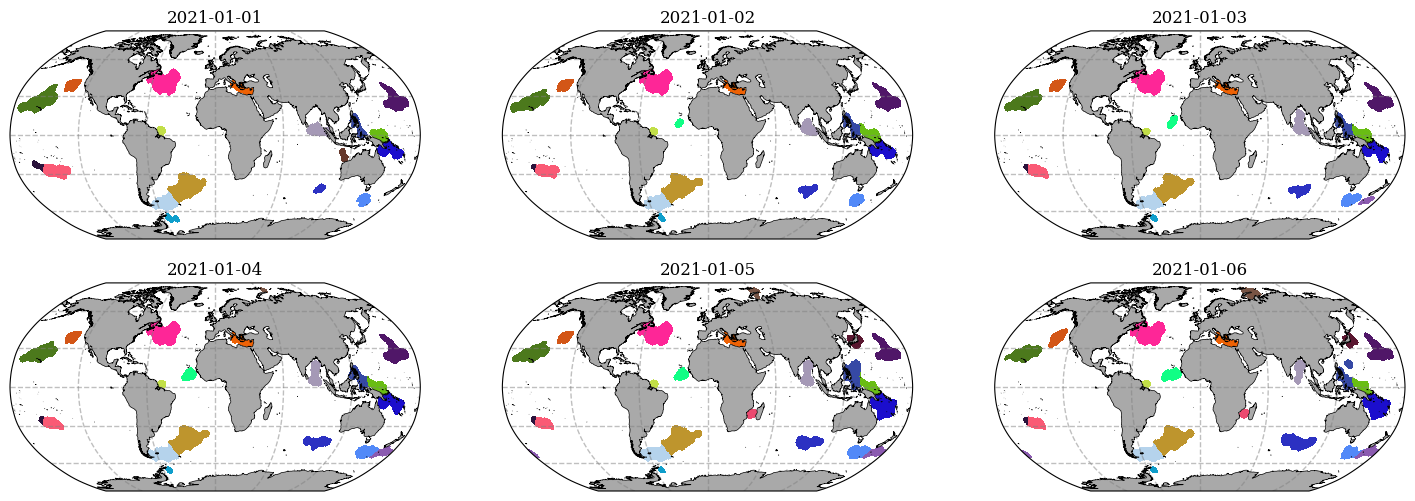

In [13]:
# Choose a subset of the ID field
ID_field_subset = ID_field.sel(time=example_days)

# Setup Plotting Configuration
config = marEx.PlotConfig(plot_IDs=True)
fig, ax = ID_field_subset.plotX.multi_plot(config, col="time", col_wrap=3);

## Plot Consecutive Months of Extreme Events

2026-10-11 22:22:13 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:22:13 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.66s


2026-10-11 22:22:13 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:22:14 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 1.05s


2026-10-11 22:22:14 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


...

2026-10-11 22:22:22 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 0.79s


2026-10-11 22:22:22 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:22:23 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 1.48s


2026-10-11 22:22:23 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:22:25 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 1.94s


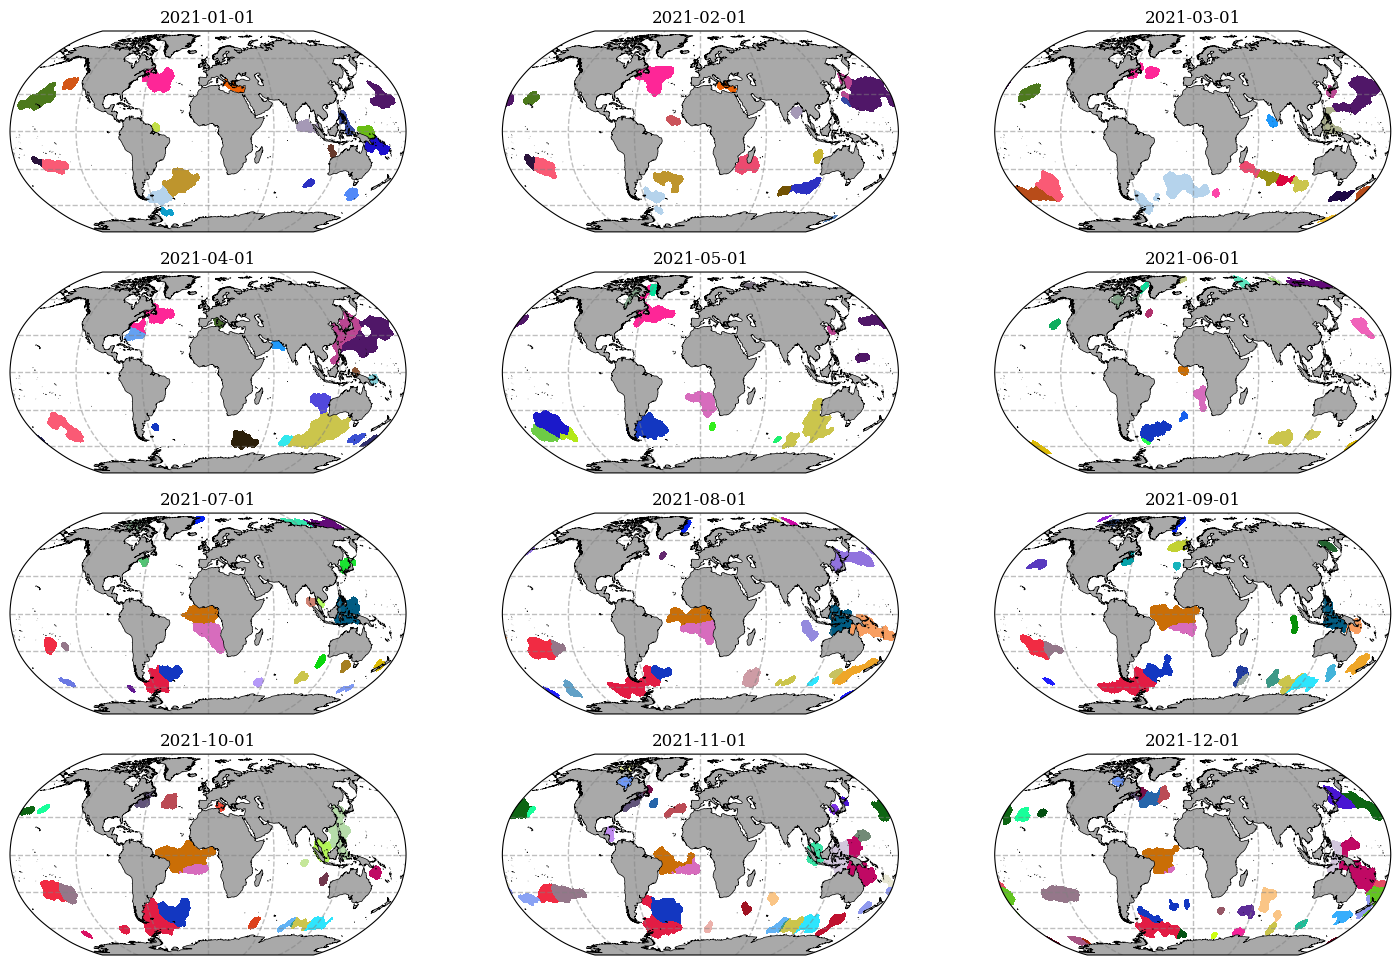

In [14]:
# Choose the first day of each month from a subset of the ID field
ID_field_subset_day1 = ID_field.sel(time=example_year).resample(time="MS").nearest()

# Setup Plotting Configuration
config = marEx.PlotConfig(plot_IDs=True)
fig, ax = ID_field_subset_day1.plotX.multi_plot(config, col="time", col_wrap=3);

## Plot Global Extreme Event Frequency

2026-10-11 22:23:18 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:23:44 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 26.69s


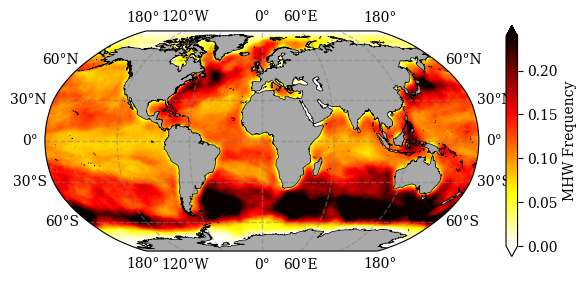

In [15]:
# Calculate the frequency of Event Occurrence
event_frequency = (ID_field > 0).mean("time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True)
fig, ax, im = event_frequency.plotX.single_plot(config)

## Plot Seasonal Extreme Event Frequency

2026-10-11 22:26:14 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:26:59 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 44.95s


2026-10-11 22:26:59 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:27:43 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 44.20s


2026-10-11 22:27:43 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:28:29 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 45.57s


2026-10-11 22:28:29 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:29:11 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 42.68s


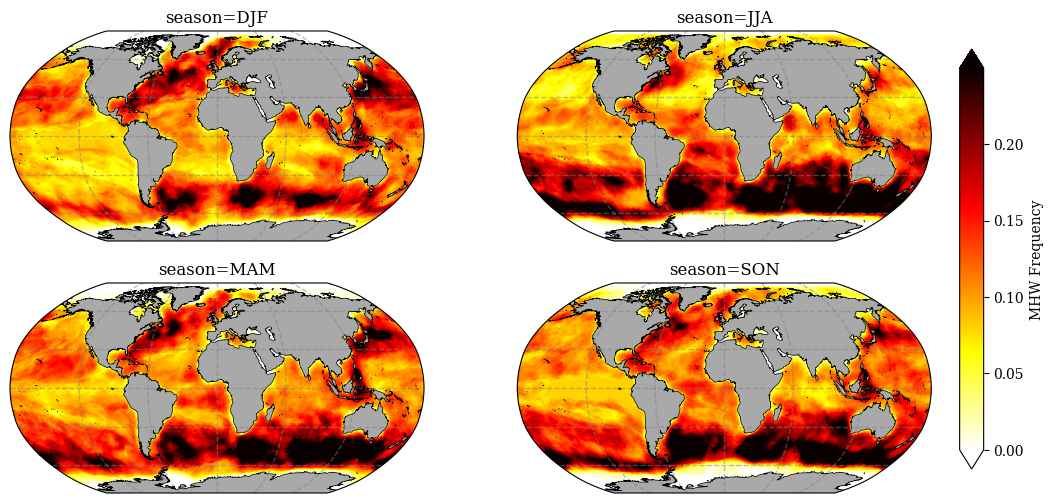

In [16]:
# Calculate the frequency of Event Occurrence per season
seasonal_frequency = (ID_field > 0).groupby("time.season").mean(dim="time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True)
fig, ax = seasonal_frequency.plotX.multi_plot(config, col="season", col_wrap=2);

## Find & Plot a Few of the Longest Events (and **The Blob**!)

In [17]:
events_duration = extreme_events_ds.time_end - extreme_events_ds.time_start
longest_events = events_duration.sortby(events_duration, ascending=False).ID

for ID in longest_events[:10].values:
    print(
        f"ID: {ID:<6}   Start Day: {extreme_events_ds.time_start.sel(ID=ID).dt.strftime('%Y-%m-%d').values}  -->  Duration: {events_duration.sel(ID=ID).dt.days.values:<4} days"
    )

ID: 5920     Start Day: 2013-10-20  -->  Duration: 1443 days
ID: 6792     Start Day: 2016-03-10  -->  Duration: 978  days
ID: 4817     Start Day: 2010-07-23  -->  Duration: 941  days
ID: 6526     Start Day: 2015-06-09  -->  Duration: 922  days
ID: 6713     Start Day: 2015-12-16  -->  Duration: 882  days


ID: 6242     Start Day: 2014-09-02  -->  Duration: 805  days
ID: 6109     Start Day: 2014-05-16  -->  Duration: 771  days
ID: 7902     Start Day: 2019-02-10  -->  Duration: 652  days
ID: 7820     Start Day: 2018-12-15  -->  Duration: 645  days
ID: 5343     Start Day: 2012-04-21  -->  Duration: 609  days


2026-10-11 22:31:09 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:33:01 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 111.80s


2026-10-11 22:33:01 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:34:50 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 109.43s


2026-10-11 22:34:50 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


...

2026-10-11 22:44:20 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 117.15s


2026-10-11 22:44:20 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:46:15 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 115.22s


2026-10-11 22:46:15 - marEx.plotX.gridded - INFO - [PID:2052064] - Starting Gridded plot rendering


2026-10-11 22:48:09 - marEx.plotX.gridded - INFO - [PID:2052064] - Completed Gridded plot rendering in 113.82s


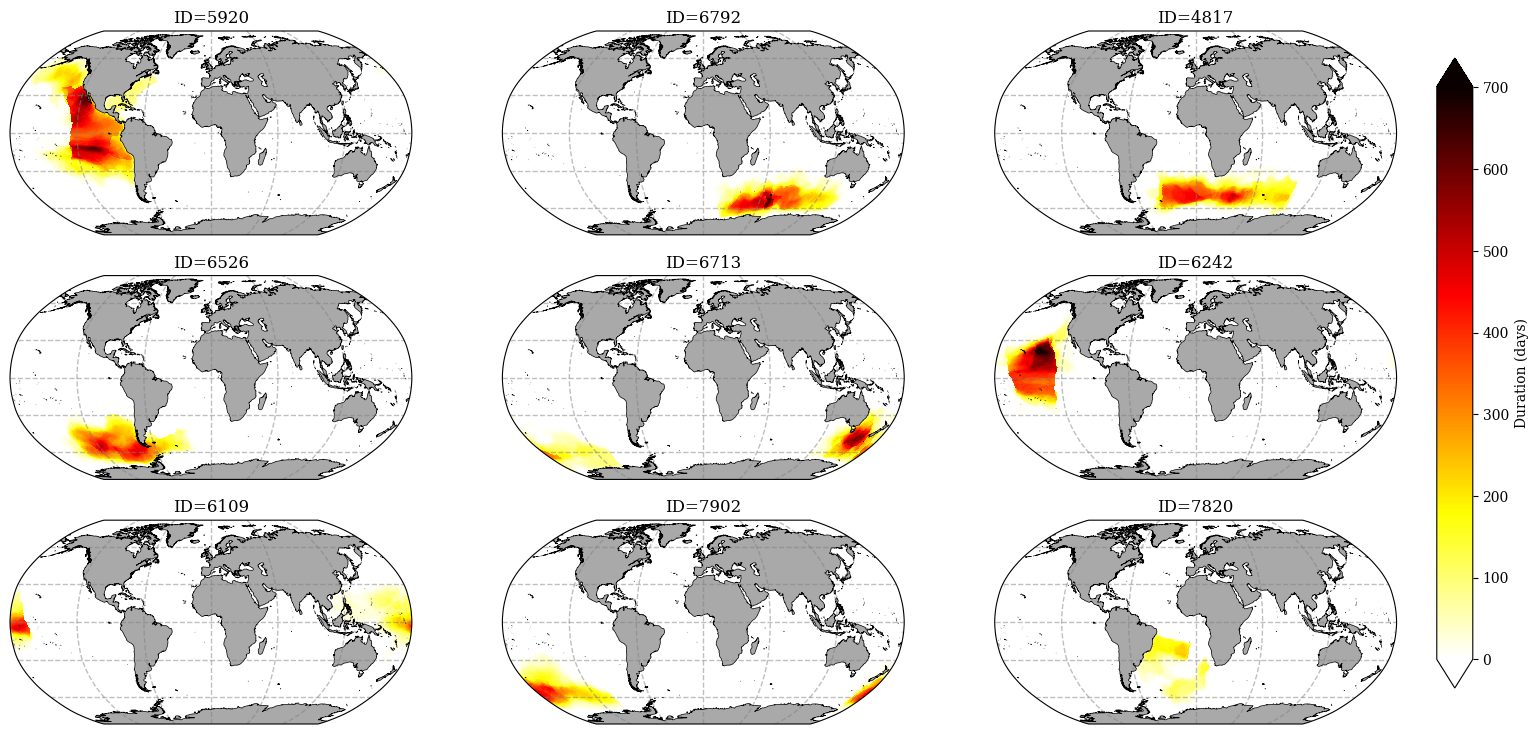

In [18]:
# Calculate the local duration of the longest events
long_events = ID_field == (longest_events[:9]).chunk({"ID": 1})
long_events_local_duration = (long_events > 0).sum("time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="Duration (days)", cmap="hot_r", cperc=[0, 100])
fig, ax = long_events_local_duration.plotX.multi_plot(config, col="ID", col_wrap=3);

## ID Maximum and Mean Event Area

In [19]:
areas_max = extreme_events_ds.area.max().compute()
print(f"Maximum object area: {areas_max.values:.0f} km²")

areas_mean = extreme_events_ds.area.mean().compute()
print(f"Mean object area: {areas_mean.values:.0f} km²")

Maximum object area: 29341846 km²


Mean object area: 2348545 km²


## Time-Series Plot of Events Area

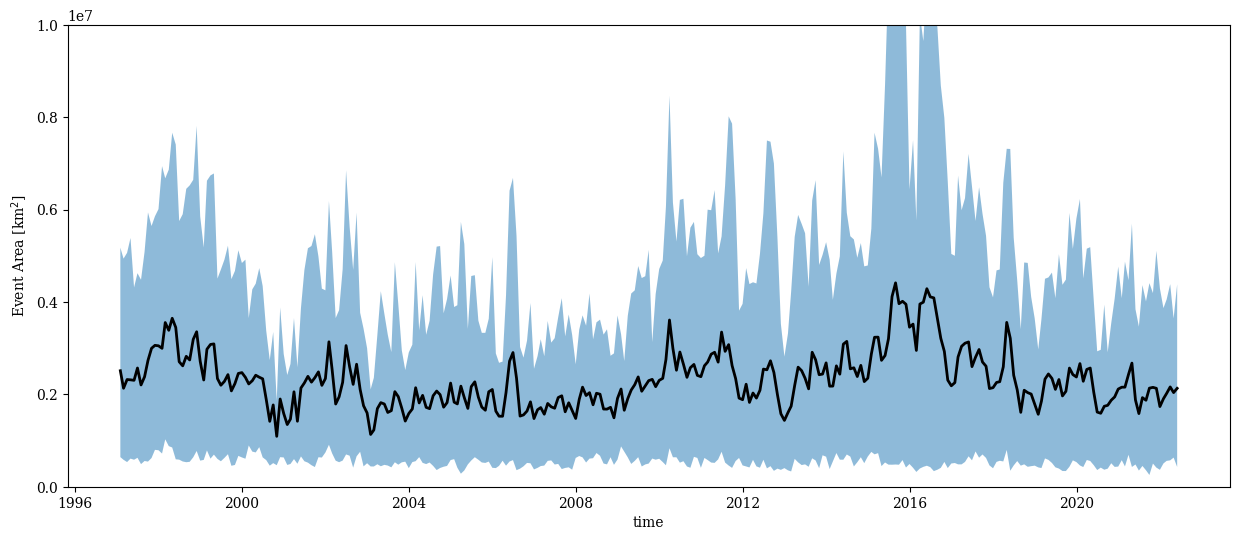

In [20]:
area = extreme_events_ds.area.chunk({"ID": 1000, "time": 100})
area_mean = area.mean("ID").resample(time="ME").mean().compute()

area_quantiles = (area.quantile([0.1, 0.9], dim="ID").resample(time="ME").mean()).compute()

area_10 = area_quantiles.sel(quantile=0.1)
area_90 = area_quantiles.sel(quantile=0.9)

plt.figure(figsize=(15, 6))
area_mean.plot(label="Mean Area", color="k", lw=2)
plt.fill_between(area_mean.time.values, area_10, area_90, alpha=0.5)
plt.ylim([0, 1e7])
plt.ylabel(r"Event Area [km$^2$]");

## Hovmüller Plot of MHW Monthly Frequency vs Latitude

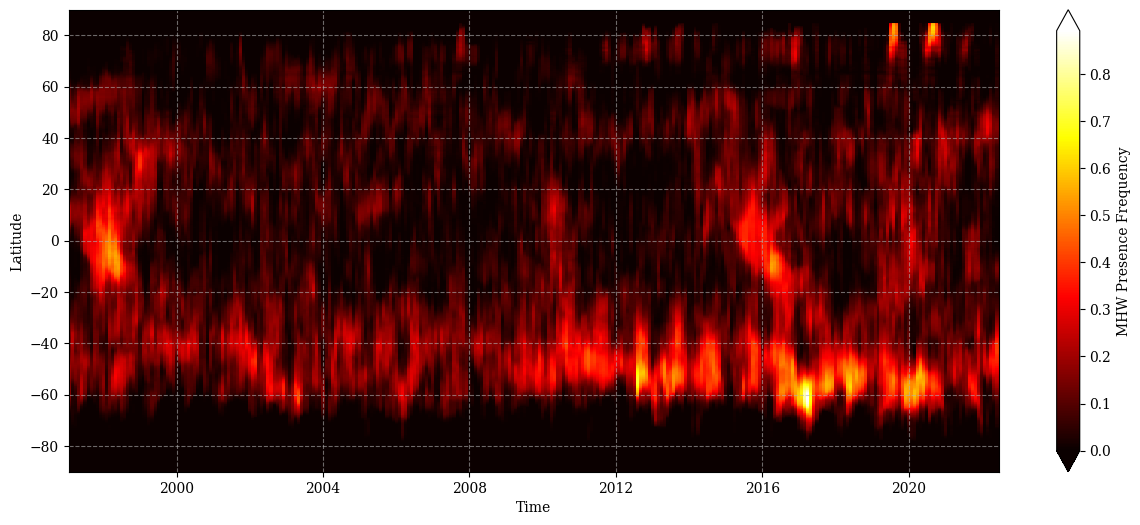

In [21]:
spatial_presence = (ID_field > 0).mean(dim="lon").resample(time="ME").mean()

fig, ax = plt.subplots(figsize=(15, 6))
im = spatial_presence.plot(
    ax=ax,
    cmap="hot",
    x="time",
    cbar_kwargs={"label": "MHW Presence Frequency", "extend": "both"},
)

ax.set_xlabel("Time")
ax.set_ylabel("Latitude")
ax.grid(True, linestyle="--", alpha=0.6)

## Seasonal Cycle of MHW vs Latitude

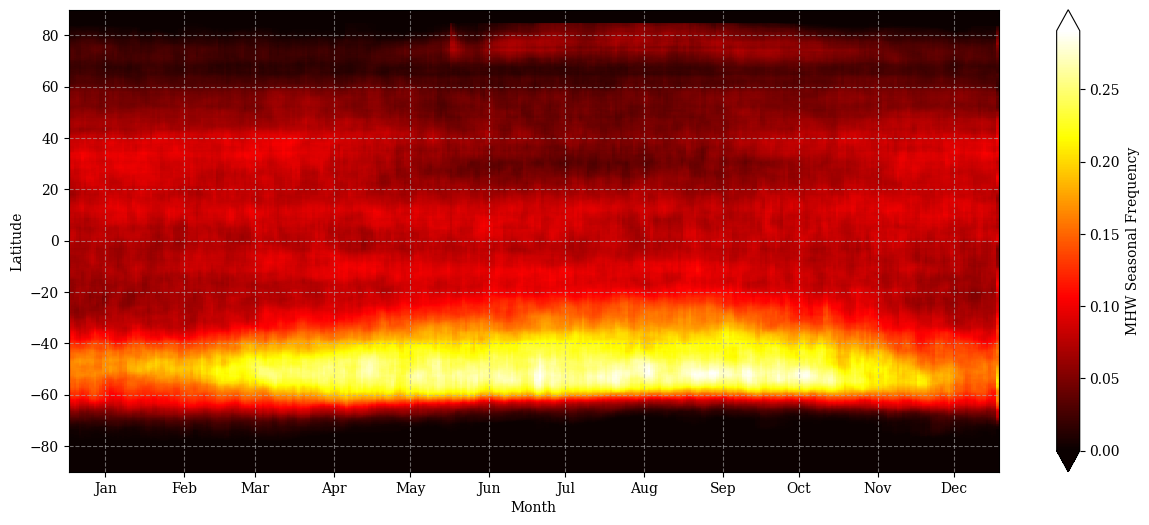

In [22]:
spatial_presence_seasonal = (ID_field > 0).mean(dim="lon").groupby("time.dayofyear").mean()

fig, ax = plt.subplots(figsize=(15, 6))
im = spatial_presence_seasonal.plot(
    ax=ax,
    cmap="hot",
    x="dayofyear",
    cbar_kwargs={"label": "MHW Seasonal Frequency", "extend": "both"},
)

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
days_per_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
month_positions = np.cumsum([0] + days_per_month[:-1]) + 15

ax.set_xticks(month_positions)
ax.set_xticklabels(months)
ax.set_xlabel("Month")
ax.set_ylabel("Latitude")
ax.grid(True, linestyle="--", alpha=0.6)

## Wall Time and Memory

One row per stage, measured while the notebook ran on the cluster configured at the top. Peak worker memory is the
summed process memory the workers report to the scheduler, which is the quantity Dask compares against `memory_limit`.
The client (this kernel) is counted separately.

In [23]:
monitor.summary()

,wall (min),peak worker memory (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,
Movie: event IDs,3.03,14.29,0.88,0.0,0
Movie: anomaly,6.59,29.34,1.06,0.0,0
Movie: basic tracking IDs,2.63,22.16,1.07,0.0,0
total,12.25,29.34,1.07,0.0,0


In [24]:
client.close()